⏳ جاري تحميل النموذج محلياً...
✅ النموذج جاهز تماماً للاستخدام!


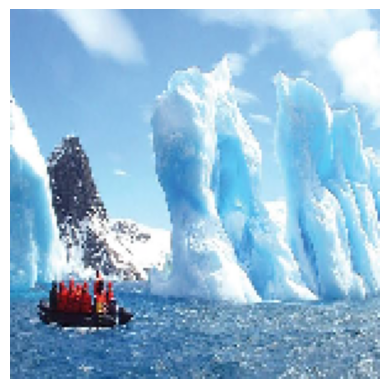

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step

🎯 نتيجة التنبؤ المحلية: [glacier] بنسبة ثقة 66.63%


In [4]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

# 1. تحديد أسماء التصنيفات ومسار الملف المحلي
# (بما أن الملف في نفس المجلد، نكتب اسمه مباشرة)
model_path = r'C:\Users\Afaq_Lite\Intel_Scenic_MobileNetV2.keras'
labels = ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']

# 2. تعريف الدالة المخصصة وتحميل النموذج إلى ذاكرة جوبتر بشكل سليم
print("⏳ جاري تحميل النموذج محلياً...")

# نقوم بتمرير الدالة ليتعرف عليها جوبتر أثناء فتح الملف
custom_objects = {'preprocess_input': tf.keras.applications.mobilenet_v2.preprocess_input}

loaded_model = tf.keras.models.load_model(model_path, custom_objects=custom_objects)
print("✅ النموذج جاهز تماماً للاستخدام!")

# 3. ضع هنا مسار أي صورة موجودة على جهازك كمثال:
# img_path = 'C:/Users/YourName/Pictures/my_image.jpg'
img_path = r'C:\Users\Afaq_Lite\Pictures\photo me\images5.jpg' 

# 4. قراءة الصورة وتجهيزها
raw_img = image.load_img(img_path, target_size=(150, 150))
final_input = np.expand_dims(image.img_to_array(raw_img), axis=0)

# 5. عرض الصورة في جوبتر
plt.imshow(raw_img)
plt.axis('off')
plt.show()

# 6. التنبؤ الفوري بالصورة
raw_predictions = loaded_model.predict(final_input)
flat_predictions = raw_predictions.flatten()

# 7. طباعة النتيجة النهائية
highest_index = np.argmax(flat_predictions)
print(f"\n🎯 نتيجة التنبؤ المحلية: [{labels[highest_index]}] بنسبة ثقة {100 * flat_predictions[highest_index]:.2f}%")

In [7]:
import gradio as gr

# 1. تحميل النموذج والتصنيفات (تأكد من وجود ملف النموذج في نفس المجلد)
model_path = r'C:\Users\Afaq_Lite\Intel_Scenic_MobileNetV2.keras'
labels = ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']

custom_objects = {'preprocess_input': tf.keras.applications.mobilenet_v2.preprocess_input}
loaded_model = tf.keras.models.load_model(model_path, custom_objects=custom_objects)

# 2. دالة المعالجة والتنبؤ الخاصة بالواجهة
def classify_scenic_image(input_image):
    if input_image is None:
        return "رجاءً قم برفع صورة أولاً."
    
    # تعديل حجم الصورة لتتطابق مع النموذج (150x150)
    img_resized = input_image.resize((150, 150))
    
    # تحويل الصورة إلى مصفوفة وإضافة بعد الدفعة
    img_array = image.img_to_array(img_resized)
    final_input = np.expand_dims(img_array, axis=0)
    
    # التنبؤ واستخراج النتائج
    raw_predictions = loaded_model.predict(final_input)
    flat_predictions = raw_predictions.flatten()
    
    # تجهيز النتائج على هيئة قاموس يعرض نسب الثقة لجميع التصنيفات
    output_dict = {labels[i]: float(flat_predictions[i]) for i in range(len(labels))}
    return output_dict

# 3. تصميم واجهة المستخدم الرسومية
with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown("<h1 style='text-align: center; color: #2b5c8f;'>🔮 كاشف المناظر الطبيعية الذكي</h1>")
    gr.Markdown("<p style='text-align: center;'>قم برفع أو سحب أي صورة تصنفها شبكتنا العصبية تلقائياً</p>")
    
    with gr.Row():
        # جهة الإدخال: لرفع الصورة
        image_input = gr.Image(type="pil", label="اختر صورة من جهازك")
        
        # جهة الإخراج: لعرض التصنيفات ونسب الثقة على هيئة بارات ملونة
        label_output = gr.Label(num_top_classes=3, label="توقعات النموذج")
        
    # زر التشغيل
    submit_btn = gr.Button("اضغط للتصنيف 🚀", variant="primary")
    submit_btn.click(fn=classify_scenic_image, inputs=image_input, outputs=label_output)

# 4. إطلاق الواجهة محلياً
demo.launch()

C:\Users\Afaq_Lite\AppData\Local\Temp\ipykernel_2712\2665187340.py:31: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step
